# ForecastIQ — Notebook 3A: Global LightGBM (28-day direct forecasting)

**Research question:** Can a machine-learning model that learns across product-store series outperform our Phase 2 statistical forecasting baselines? Does adding weekday/calendar information help?

**Read one section at a time.** This notebook uses the *same 400 stratified M5 series* and reserves the **same last 28 days** for the final test. Each supervised row represents an **origin × series × forecast horizon**; features describe only information observable at that origin. A 28-day forecast is produced **without seeing any sales within those 28 days**.

Two ablation experiments: **LightGBM A (no calendar)** and **LightGBM B (+ weekday and month)**. Both use identical splits and history features. The notebook also evaluates fixed SES, SBA and TSB baselines using parameter values selected on validation only.

> Sales may differ from true demand if a product was unavailable. Model comparison on 400 equally sampled series is a pilot, not a population-wide M5 leaderboard.


In [15]:
# Shared scientifically validated ForecastIQ framework
import sys
from pathlib import Path
_project = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
if str(_project) not in sys.path:
    sys.path.insert(0, str(_project))
from src.experiments.config import ExperimentConfig, save_manifest
EXPERIMENT_CONFIG = ExperimentConfig()
EXPERIMENT_NAME = '03_global_machine_learning_forecasting'
MANIFEST = save_manifest(_project / 'results' / 'manifests' / (EXPERIMENT_NAME + '.json'), EXPERIMENT_NAME, EXPERIMENT_CONFIG, sources=[_project / 'data' / 'raw' / 'sales_train_validation.csv'])
print('Experiment manifest:', MANIFEST['experiment_id'])


Experiment manifest: 03_global_machine_learning_forecasting-20261101T103110Z


## 1 — Dependencies and project paths
Install once if needed: `%pip install lightgbm pandas numpy scikit-learn matplotlib nbformat` (restart kernel after installing).

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import mean_absolute_error
try:
    import lightgbm as lgb
except ImportError as e:
    raise ImportError('Install LightGBM with: %pip install lightgbm') from e

PROJECT = Path.cwd()
if not (PROJECT / 'data').exists() and (PROJECT.parent / 'data').exists():
    PROJECT = PROJECT.parent
RAW = PROJECT / 'data' / 'raw'
OUT = PROJECT / 'data' / 'processed'
OUT.mkdir(parents=True, exist_ok=True)
SALES_FILE = OUT / 'm5_sample_400.csv'
META_FILE = OUT / 'm5_sample_400_metadata.csv'
assert SALES_FILE.exists() and META_FILE.exists(), 'Run Notebook 1 first to create the 400-series sample.'
SEED = 42
HORIZON = 28
N_FOLDS = 3
ORIGIN_STEP = 28   # historic forecast origins, never overlapping labels for one origin
MIN_HISTORY = 112
MAX_SERIES = None  # e.g. 80 for a quick smoke test; None => all 400
print('Project:', PROJECT)
print('LightGBM version:', lgb.__version__)

## 2 — Load and validate the same Phase 1 sample
`series_id = item_id + "__" + store_id`. Categories are imported from Notebook 1, not recomputed with test-period information.

In [17]:
sales = pd.read_csv(SALES_FILE)
meta = pd.read_csv(META_FILE)
day_cols = sorted([c for c in sales if c.startswith('d_') and c[2:].isdigit()], key=lambda c:int(c[2:]))
assert day_cols and len(day_cols) > MIN_HISTORY + (N_FOLDS+2)*HORIZON
assert sales.series_id.is_unique and meta.series_id.is_unique
s = sales.merge(meta[['series_id','demand_type']], on='series_id', validate='one_to_one')
if MAX_SERIES is not None:
    s = s.groupby('demand_type', group_keys=False).head(max(1, MAX_SERIES // 4)).reset_index(drop=True)
values = s[day_cols].apply(pd.to_numeric, errors='coerce')
assert values.notna().all().all(), 'Missing or invalid sales detected'
assert (values >= 0).all().all(), 'Negative sales detected'
Y = values.to_numpy(dtype=np.float32)
S, T = Y.shape
assert S >= 4
ids = s['series_id'].to_numpy()
label_types = s['demand_type'].to_numpy()
test_origin = T-HORIZON
print(f'{S} series × {T} days; train through d_{test_origin}; test d_{test_origin+1}…d_{T}')
display(s.demand_type.value_counts().rename_axis('demand_type').to_frame('series'))

400 series × 1913 days; train through d_1885; test d_1886…d_1913


,series
demand_type,
Smooth,100
Erratic,100
Intermittent,100
Lumpy,100


## 3 — Calendar mapping (known future information only)
M5 `calendar.csv` provides the mapping from day labels (`d_1`, etc.) to dates. Calendar features are legitimately available for the forecast horizon. **We do not use future sales or future observed prices.**

In [18]:
calendar_path = RAW / 'calendar.csv'
if calendar_path.exists():
    calendar = pd.read_csv(calendar_path, usecols=['d','date']).drop_duplicates('d')
    day_dates = pd.to_datetime(calendar.set_index('d').reindex(day_cols)['date'])
    assert day_dates.notna().all(), 'calendar.csv is missing required d_ dates'
    DATE_SOURCE = 'calendar.csv'
else:
    # M5 day d_1 is 2011-01-29. Verify against official calendar if it becomes available.
    day_dates = pd.Series(pd.date_range('2011-01-29', periods=T, freq='D'), index=day_cols)
    DATE_SOURCE = 'M5 d_1 fallback (2011-01-29)'
dates = pd.DatetimeIndex(day_dates.to_numpy())
print('Date source:', DATE_SOURCE, '| first:', dates[0].date(), '| last:', dates[-1].date())

Date source: calendar.csv | first: 2011-01-29 | last: 2016-04-24


## 4 — Understand direct multi-horizon forecasting
At an origin `o`, we have observed `Y[:, :o]`. To predict the next 28 days, we create **28 rows for each series**, one for each horizon `h=1…28`. All lag/rolling features are fixed at `o`; only known horizon information (horizon number, future weekday/month) changes. This is **not** a one-step model fed actual future sales.

In [19]:
# Reload so an already-running Jupyter kernel cannot retain an older feature schema.
from importlib import reload
import src.features.feature_engineering as feature_engineering
feature_engineering = reload(feature_engineering)

def snapshot_features(history):
    output = feature_engineering.historical_snapshot(history)
    required = {'last_28_vs_prev_28'}
    missing = required.difference(output)
    if missing:
        raise RuntimeError(f'Shared feature schema is missing: {sorted(missing)}')
    return output

# Series code is a categorical indicator. Demand type is not used as a feature.
series_index = np.arange(S, dtype=np.int32)

def make_origin_rows(origin, with_target=True):
    # Create S x horizon rows using history strictly before origin.
    assert MIN_HISTORY <= origin <= T-HORIZON
    snap = snapshot_features(Y[:, :origin])
    rows = {key: np.repeat(value, HORIZON) for key, value in snap.items()}
    rows['series_code'] = np.repeat(series_index, HORIZON)
    rows['horizon'] = np.tile(np.arange(1, HORIZON+1, dtype=np.int16), S)
    future_dates = dates[origin:origin+HORIZON]
    rows['day_of_week'] = np.tile(future_dates.dayofweek.to_numpy(dtype=np.int8), S)
    rows['month'] = np.tile(future_dates.month.to_numpy(dtype=np.int8), S)
    frame = pd.DataFrame(rows)
    if with_target:
        return frame, Y[:,origin:origin+HORIZON].reshape(-1)
    return frame

example_x, example_y = make_origin_rows(test_origin)
display(example_x.head(7))
print('28 future prediction rows per series:', len(example_x), 'total')


,lag_1,lag_7,lag_14,lag_28,lag_56,mean_7,std_7,zero_ratio_7,mean_28,std_28,zero_ratio_28,mean_56,std_56,zero_ratio_56,last_28_vs_prev_28,series_code,horizon,day_of_week,month
0,3.0,0.0,14.0,0.0,0.0,4.428571,9.678506,0.714286,4.357143,6.735908,0.571429,2.178571,5.237595,0.785714,4.357143,0,1,0,3
1,3.0,0.0,14.0,0.0,0.0,4.428571,9.678506,0.714286,4.357143,6.735908,0.571429,2.178571,5.237595,0.785714,4.357143,0,2,1,3
2,3.0,0.0,14.0,0.0,0.0,4.428571,9.678506,0.714286,4.357143,6.735908,0.571429,2.178571,5.237595,0.785714,4.357143,0,3,2,3
3,3.0,0.0,14.0,0.0,0.0,4.428571,9.678506,0.714286,4.357143,6.735908,0.571429,2.178571,5.237595,0.785714,4.357143,0,4,3,3
4,3.0,0.0,14.0,0.0,0.0,4.428571,9.678506,0.714286,4.357143,6.735908,0.571429,2.178571,5.237595,0.785714,4.357143,0,5,4,4
5,3.0,0.0,14.0,0.0,0.0,4.428571,9.678506,0.714286,4.357143,6.735908,0.571429,2.178571,5.237595,0.785714,4.357143,0,6,5,4
6,3.0,0.0,14.0,0.0,0.0,4.428571,9.678506,0.714286,4.357143,6.735908,0.571429,2.178571,5.237595,0.785714,4.357143,0,7,6,4


28 future prediction rows per series: 11200 total


## 5 — Time-based folds and strict leakage checks
Each validation fold predicts one 28-day block. Training origins are only included when their *entire 28-day label window finishes before* the validation origin. We never train on labels from validation/test horizons.

In [20]:
validation_origins = [test_origin-HORIZON*i for i in range(N_FOLDS,0,-1)]
assert validation_origins[-1]+HORIZON == test_origin

def training_origins_before(origin):
    return list(range(MIN_HISTORY, origin-HORIZON+1, ORIGIN_STEP))

for origin in validation_origins + [test_origin]:
    origins = training_origins_before(origin)
    assert origins and max(origins)+HORIZON <= origin
    print('forecast origin:', origin, '| historical training origins:', len(origins),
          '| final train label ends:', max(origins)+HORIZON,
          '| forecast days:', f'{origin+1}..{origin+HORIZON}')

# Demonstrate that changing validation future sales does not modify validation features.
probe = test_origin
first_snapshot = make_origin_rows(probe, with_target=False)
original = Y[0, probe]
Y[0, probe] = original + 1234
second_snapshot = make_origin_rows(probe, with_target=False)
Y[0, probe] = original
pd.testing.assert_frame_equal(first_snapshot, second_snapshot)
print('Leakage smoke test PASSED: features do not depend on future actual sales.')

forecast origin: 1801 | historical training origins: 60 | final train label ends: 1792 | forecast days: 1802..1829
forecast origin: 1829 | historical training origins: 61 | final train label ends: 1820 | forecast days: 1830..1857
forecast origin: 1857 | historical training origins: 62 | final train label ends: 1848 | forecast days: 1858..1885
forecast origin: 1885 | historical training origins: 63 | final train label ends: 1876 | forecast days: 1886..1913
Leakage smoke test PASSED: features do not depend on future actual sales.


## 6 — Assemble supervised examples and train LightGBM
Global learning means **one model shares information across all series**. The product-store identifier is treated as categorical, and horizon is an explicit feature. To reduce runtime, forecast origins are sampled every 28 days. This is a pilot design rather than an exhaustive hyperparameter search.

In [21]:
from src.forecasting.lightgbm_direct import fit_predict_frames
BASE_FEATURES = ['series_code','horizon','lag_1','lag_7','lag_14','lag_28','lag_56',
                 'mean_7','std_7','zero_ratio_7','mean_28','std_28','zero_ratio_28',
                 'mean_56','std_56','zero_ratio_56','last_28_vs_prev_28']
CAL_FEATURES = ['day_of_week','month']

def data_before(origin, calendar_on):
    pairs=[make_origin_rows(o) for o in training_origins_before(origin)]
    feature_names=BASE_FEATURES+(CAL_FEATURES if calendar_on else [])
    X=pd.concat([x for x,_ in pairs],ignore_index=True)[feature_names]
    X['series_code']=X['series_code'].astype('category')
    return X,np.concatenate([y for _,y in pairs])

def fit_and_forecast(origin, calendar_on):
    X_train,y_train=data_before(origin,calendar_on)
    feature_names=list(X_train.columns)
    X_future=make_origin_rows(origin,with_target=False)[feature_names].copy()
    X_future['series_code']=pd.Categorical(X_future['series_code'],categories=X_train['series_code'].cat.categories)
    prediction,model=fit_predict_frames(X_train,y_train,X_future,
        params={'random_state':SEED},categorical_features=['series_code'])
    return prediction.reshape(S,HORIZON),model,len(X_train)

print('Features WITHOUT calendar:',BASE_FEATURES)
print('Extra calendar features:',CAL_FEATURES)


Features WITHOUT calendar: ['series_code', 'horizon', 'lag_1', 'lag_7', 'lag_14', 'lag_28', 'lag_56', 'mean_7', 'std_7', 'zero_ratio_7', 'mean_28', 'std_28', 'zero_ratio_28', 'mean_56', 'std_56', 'zero_ratio_56', 'last_28_vs_prev_28']
Extra calendar features: ['day_of_week', 'month']


## 7 — Chronological cross-validation for both ML variants
The **same three validation periods** are used for both A and B. We compare out-of-sample MAE, not training score. This section trains six models and may take time on a CPU.

In [22]:
cv_records=[]
for fold,origin in enumerate(validation_origins,1):
    truth = Y[:,origin:origin+HORIZON]
    for calendar_on, name in [(False,'LightGBM_A_no_calendar'),(True,'LightGBM_B_calendar')]:
        prediction, fitted, train_rows = fit_and_forecast(origin, calendar_on)
        cv_records.append({'fold':fold,'origin':origin,'model':name,
                           'MAE':float(np.abs(truth-prediction).mean()),
                           'train_rows':train_rows})
        print('fold',fold,'model',name,'MAE',round(cv_records[-1]['MAE'],4),'training rows',train_rows)
cv_scores = pd.DataFrame(cv_records)
display(cv_scores.pivot(index='fold',columns='model',values='MAE'))
display(cv_scores.groupby('model',as_index=False)['MAE'].mean().sort_values('MAE'))

fold 1 model LightGBM_A_no_calendar MAE 2.1412 training rows 672000
fold 1 model LightGBM_B_calendar MAE 2.0595 training rows 672000
fold 2 model LightGBM_A_no_calendar MAE 2.1581 training rows 683200
fold 2 model LightGBM_B_calendar MAE 2.1135 training rows 683200
fold 3 model LightGBM_A_no_calendar MAE 2.1308 training rows 694400
fold 3 model LightGBM_B_calendar MAE 2.0706 training rows 694400


model,LightGBM_A_no_calendar,LightGBM_B_calendar
fold,,
1,2.141187,2.059482
2,2.158091,2.113471
3,2.130800,2.070623


,model,MAE
1,LightGBM_B_calendar,2.081192
0,LightGBM_A_no_calendar,2.143359


## 8 — Select the LightGBM variant using validation only
Only the **three validation folds** choose between versions A and B. The final test period remains untouched. We will still report BOTH variants on test to make the ablation transparent.

In [23]:
cv_mean = cv_scores.groupby('model')['MAE'].mean().sort_values()
selected_ml = cv_mean.index[0]
print('Chosen LightGBM variant (validation only):', selected_ml)
ml_test_pred = {}
ml_models = {}
for calendar_on, name in [(False,'LightGBM_A_no_calendar'),(True,'LightGBM_B_calendar')]:
    pred, model, nrows = fit_and_forecast(test_origin, calendar_on)
    ml_test_pred[name] = pred
    ml_models[name] = model
    print(name, 'trained on', nrows, 'rows; 28-day forecast produced')

Chosen LightGBM variant (validation only): LightGBM_B_calendar
LightGBM_A_no_calendar trained on 705600 rows; 28-day forecast produced
LightGBM_B_calendar trained on 705600 rows; 28-day forecast produced


## 9 — Statistical reference models (SES, SBA, TSB)
For a fair *time-period comparison*, each statistical model forecasts the same 28-day origins. Their smoothing parameter is selected **separately for each series using only the three pre-test validation folds**. This broadly follows our Phase 2 approach, but exact results may differ if Phase 2 used different parameter grids/initialization or excluded some series. We do **not** select parameters using test errors.

In [24]:
from src.forecasting.statistical_models import forecast_ses, forecast_sba, forecast_tsb
ALPHAS = EXPERIMENT_CONFIG.alphas

def statistical_rate(history, method, alpha):
    fn = {'SES': forecast_ses, 'SBA': forecast_sba, 'TSB': forecast_tsb}[method]
    return float(fn(history, 1, alpha=alpha)[0])

baseline_pred={}
stat_param_rows=[]
for method in ('SES','SBA','TSB'):
    result=np.zeros((S,HORIZON),dtype=np.float32)
    for i in range(S):
        errors=[]
        for alpha in ALPHAS:
            fold_errors=[]
            for origin in validation_origins:
                rate=statistical_rate(Y[i,:origin],method,alpha)
                fold_errors.append(np.abs(Y[i,origin:origin+HORIZON]-rate).mean())
            errors.append(float(np.mean(fold_errors)))
        best_alpha=ALPHAS[int(np.argmin(errors))]
        rate=statistical_rate(Y[i,:test_origin],method,best_alpha)
        result[i,:]=rate
        stat_param_rows.append({'series_id':ids[i],'model':method,'alpha':best_alpha,'cv_MAE':min(errors)})
    baseline_pred[method]=result
    print(method,'test forecast complete')
stat_params=pd.DataFrame(stat_param_rows)
print('Validation-selected alpha counts:')
display(stat_params.groupby(['model','alpha']).size().rename('series_count').reset_index())


SES test forecast complete
SBA test forecast complete
TSB test forecast complete
Validation-selected alpha counts:


,model,alpha,series_count
0,SBA,0.1,204
1,SBA,0.2,46
2,SBA,0.3,150
3,SES,0.1,265
4,SES,0.2,47
5,SES,0.3,88
6,TSB,0.1,258
7,TSB,0.2,48
8,TSB,0.3,94


## 10 — Test metrics: MAE, MASE, aggregate WAPE, bias and cost proxy
**MASE** uses mean absolute one-step naive differences from the *pre-test training history*. **WAPE** is computed by dividing summed absolute errors by summed actual sales, not by averaging per-series WAPE. `bias = prediction − actual`. Hypothetical cost proxy is daily underforecast × 5 plus overforecast × 1; this is **not** a stock replenishment simulator.

In [25]:
from src.evaluation.metrics import series_metric_records, aggregate_metric_records
truth=Y[:,test_origin:]
train=Y[:,:test_origin]
all_predictions={**baseline_pred,**ml_test_pred}
metric_rows=series_metric_records(truth,all_predictions,train,ids,label_types,
                                  underforecast_penalty=5.,overforecast_penalty=1.)
leaderboard=(metric_rows.groupby('model').apply(aggregate_metric_records,include_groups=False)
             .reset_index().sort_values('MAE'))
by_type=(metric_rows.groupby(['demand_type','model']).apply(aggregate_metric_records,include_groups=False)
         .reset_index())
display(leaderboard.round(4))
display(by_type[['demand_type','model','series','MAE','MASE','RMSSE','WAPE_pct','bias']].round(4))
print('Validation-selected ML:',selected_ml,'| Test MAE:',round(float(leaderboard.set_index('model').loc[selected_ml,'MAE']),4))


,model,series,MAE,MASE,valid_MASE,RMSSE,valid_RMSSE,WAPE_pct,bias,total_cost_proxy
1,LightGBM_B_calendar,400.0,2.0392,1.5581,400.0,0.8851,400.0,63.6534,0.1967,64110.0410
4,TSB,400.0,2.0681,1.5742,400.0,0.9099,400.0,64.5574,0.1241,66708.7981
3,SES,400.0,2.0697,1.5729,400.0,0.9119,400.0,64.6064,0.1188,66881.3824
0,LightGBM_A_no_calendar,400.0,2.1184,1.6017,400.0,0.9108,400.0,66.1271,0.1827,67086.9596
2,SBA,400.0,2.2018,1.6147,400.0,0.9354,400.0,68.7281,0.0878,72011.2302


,demand_type,model,series,MAE,MASE,RMSSE,WAPE_pct,bias
0,Erratic,LightGBM_A_no_calendar,100.0,3.6107,1.1187,0.8087,71.9513,0.6248
1,Erratic,LightGBM_B_calendar,100.0,3.5450,1.0932,0.7912,70.6419,0.6973
2,Erratic,SBA,100.0,3.7934,1.2168,0.8573,75.5927,0.3662
3,Erratic,SES,100.0,3.5623,1.1304,0.8200,70.9866,0.3325
4,Erratic,TSB,100.0,3.5529,1.1232,0.8149,70.7992,0.3486
5,Intermittent,LightGBM_A_no_calendar,100.0,0.6873,1.9257,0.9833,113.6643,0.0064
6,Intermittent,LightGBM_B_calendar,100.0,0.6776,1.9072,0.9652,112.0582,0.0059
7,Intermittent,SBA,100.0,0.8337,1.9237,1.0134,137.8880,0.1121
8,Intermittent,SES,100.0,0.6733,1.9056,0.9957,111.3518,-0.0213
9,Intermittent,TSB,100.0,0.6675,1.9038,0.9892,110.3969,-0.0224


Validation-selected ML: LightGBM_B_calendar | Test MAE: 2.0392


## 11 — Did weekday/month improve validation and test accuracy?
A/B comparison isolates the value of these two calendar features **within this particular LightGBM setup**. Do not choose the winner based on test MAE; compare the validation choice to test behavior.

Validation comparison:


,mean_cv_MAE
model,
LightGBM_B_calendar,2.081192
LightGBM_A_no_calendar,2.143359


Final test comparison (reported after validation selection):


,model,MAE,MASE,WAPE_pct,bias
1,LightGBM_B_calendar,2.039182,1.558145,63.653399,0.196718
0,LightGBM_A_no_calendar,2.118427,1.601657,66.127056,0.182688


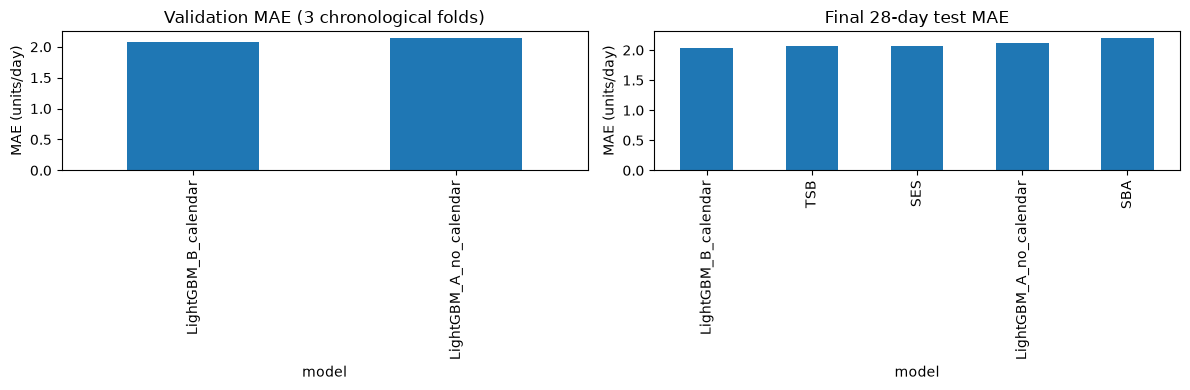

In [26]:
print('Validation comparison:')
display(cv_mean.to_frame('mean_cv_MAE'))
print('Final test comparison (reported after validation selection):')
display(leaderboard[leaderboard.model.str.startswith('LightGBM')][['model','MAE','MASE','WAPE_pct','bias']])
fig,axs=plt.subplots(1,2,figsize=(12,4))
cv_mean.plot.bar(ax=axs[0],title='Validation MAE (3 chronological folds)')
leaderboard.set_index('model')['MAE'].sort_values().plot.bar(ax=axs[1],title='Final 28-day test MAE')
axs[0].set_ylabel('MAE (units/day)');axs[1].set_ylabel('MAE (units/day)')
plt.tight_layout();plt.show()

## 12 — Visual examples: forecast trajectories
Direct models can forecast a different value for each of the 28 days. SES/SBA/TSB produce constant rates over a fixed forecast origin. Inspect several series instead of relying on aggregate scores alone.

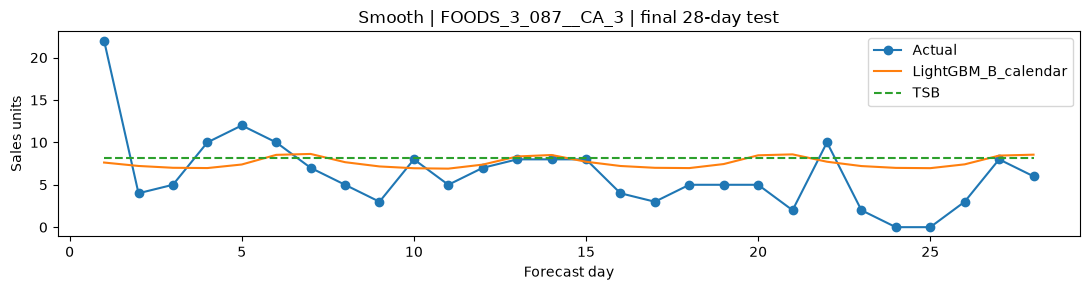

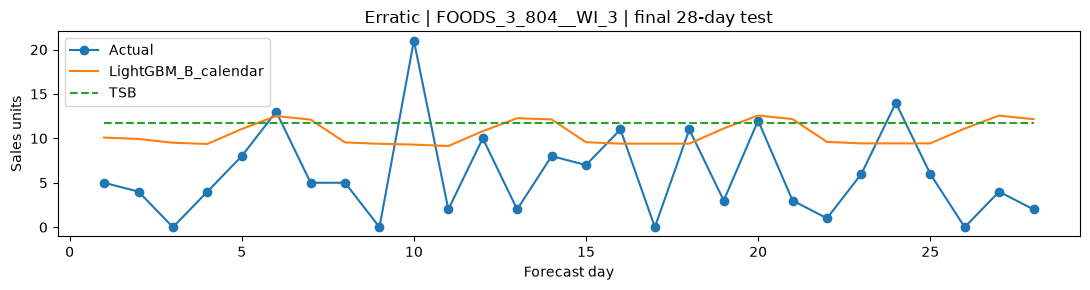

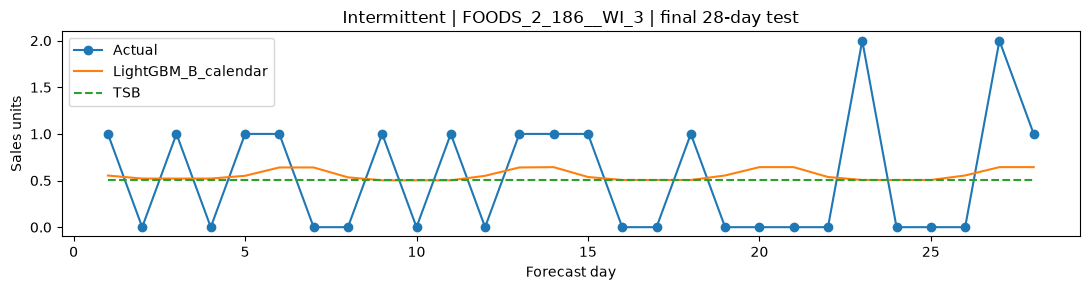

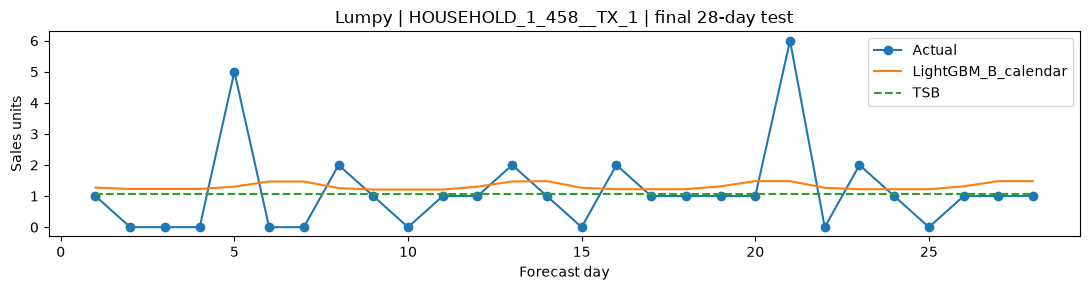

In [27]:
rng=np.random.default_rng(SEED)
for demand_type in ['Smooth','Erratic','Intermittent','Lumpy']:
    matches=np.flatnonzero(label_types==demand_type)
    if len(matches)==0:continue
    i=int(rng.choice(matches))
    plt.figure(figsize=(11,3))
    x=np.arange(1,HORIZON+1)
    plt.plot(x,truth[i],marker='o',label='Actual')
    plt.plot(x,ml_test_pred[selected_ml][i],label=selected_ml)
    plt.plot(x,baseline_pred['TSB'][i],linestyle='--',label='TSB')
    plt.title(f'{demand_type} | {ids[i]} | final 28-day test')
    plt.xlabel('Forecast day');plt.ylabel('Sales units');plt.legend();plt.tight_layout();plt.show()

## 13 — Export reproducible results

In [ ]:
cv_scores.to_csv(OUT/'phase3a_lightgbm_cv_scores.csv',index=False)
leaderboard.to_csv(OUT/'phase3a_model_test_overall.csv',index=False)
by_type.to_csv(OUT/'phase3a_model_test_by_type.csv',index=False)
metric_rows.to_csv(OUT/'phase3a_model_test_per_series.csv',index=False)
stat_params.to_csv(OUT/'phase3a_baseline_selected_alphas.csv',index=False)
forecasts=[]
for name,pred in all_predictions.items():
    forecasts.append(pd.DataFrame({'series_id':np.repeat(ids,HORIZON),
        'demand_type':np.repeat(label_types,HORIZON),'model':name,
        'horizon':np.tile(np.arange(1,HORIZON+1),S),
        'actual':truth.reshape(-1),'prediction':pred.reshape(-1)}))
pd.concat(forecasts,ignore_index=True).to_csv(OUT/'phase3a_all_test_forecasts.csv',index=False)
print('Files saved to:',OUT)
print('\nNotes for interpretation:')
print('• This is direct 28-step prediction; no actual future sales are used as lag inputs.')
print('• Test performance cannot be used for tuning features, choosing models or alpha.')
print('• 400 balanced series are not representative of all Walmart series.')
print('• Price, events, and full-population learning are potential later experiments.')

## 14 — How this prepares Agentic AI

- **Data agent:** inspect demand categories, recent zeros, recent demand shifts.
- **Forecasting agent:** call well-defined statistical and ML forecasting tools.
- **Evaluation agent:** compare identical chronological folds, MASE, WAPE, bias and business-cost proxies.
- **Planning/reflection agent:** propose a new experiment only when diagnostics or uncertainty justify it, and request human approval for consequential changes.

**After running:** share `phase3a_lightgbm_cv_scores.csv` and `phase3a_model_test_overall.csv`; we will check if LightGBM improves over the statistical methods, whether calendar features add value, and whether Phase 3B (hurdle model) is justified.

### Limitations
- Global model is trained on the same 400-series research sample, *not* all M5 items.
- The model is a regression baseline, not a probabilistic count model; predictions are clipped at zero.
- Price and promotional events are not included yet. Month and weekday are known in advance.
- Selected statistical baseline parameters and initialization may differ from Notebook 2; reproduce exact Phase 2 methods if strict numerical matching is needed.
- With M5's `sales_train_validation.csv`, the held-out last 28 days are historical days from the file, not the separate Kaggle evaluation-period leaderboard.
